In [118]:
#可以使可视化图表在每串代码之后的命令
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']#设置绘图时的字体
plt.rcParams['axes.unicode_minus']=False#坐标轴上的负号用减号表示

In [119]:
df=pd.read_csv(r"E:/jupyter项目练习/RFM-RFI用户价值分层与ROI优化/user_personalized_features.csv")
print(df.head())

   Unnamed: 0 User_ID  Age  Gender  Location  Income   Interests  \
0           0      #1   56    Male  Suburban   38037      Sports   
1           1      #2   46  Female     Rural  103986  Technology   
2           2      #3   32  Female  Suburban  101942      Sports   
3           3      #4   60  Female  Suburban   71612     Fashion   
4           4      #5   25    Male  Suburban   49725      Travel   

   Last_Login_Days_Ago  Purchase_Frequency  Average_Order_Value  \
0                    5                   7                   18   
1                   15                   7                  118   
2                   28                   1                  146   
3                   18                   3                  163   
4                    2                   5                  141   

   Total_Spending Product_Category_Preference  Time_Spent_on_Site_Minutes  \
0            2546                       Books                         584   
1             320                 

In [120]:
#查看数据的整体情况
print(f"数据规模:{df.shape}")

数据规模:(1000, 15)


In [121]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Unnamed: 0                   1000 non-null   int64 
 1   User_ID                      1000 non-null   object
 2   Age                          1000 non-null   int64 
 3   Gender                       1000 non-null   object
 4   Location                     1000 non-null   object
 5   Income                       1000 non-null   int64 
 6   Interests                    1000 non-null   object
 7   Last_Login_Days_Ago          1000 non-null   int64 
 8   Purchase_Frequency           1000 non-null   int64 
 9   Average_Order_Value          1000 non-null   int64 
 10  Total_Spending               1000 non-null   int64 
 11  Product_Category_Preference  1000 non-null   object
 12  Time_Spent_on_Site_Minutes   1000 non-null   int64 
 13  Pages_Viewed                 1000 

根据数据的整体特征情况，将特征进行分类处理（按业务划分是谁，逛啥，花啥）

基本信息：用户id，年龄，性别，地域，收入，兴趣，

行为特征：距上次登录间隔时间，浏览网站时间，浏览页面数，是否订阅

消费特征：购买频率，平均订单价值，总花费，产品种类偏好，

In [122]:
stats = df.describe().loc[['mean', '50%', 'min', 'max']]
stats.loc['mode'] = df.mode().iloc[0]
stats


,Unnamed: 0,Age,Income,Last_Login_Days_Ago,Purchase_Frequency,Average_Order_Value,Total_Spending,Time_Spent_on_Site_Minutes,Pages_Viewed
mean,499.5,40.986,81304.732,15.586,4.631,104.039,2552.957,297.36,24.403
50%,499.5,42.000,81042.000,16.000,5.000,105.000,2542.000,292.50,24.500
min,0.0,18.000,20155.000,1.000,0.000,10.000,112.000,2.00,1.000
max,999.0,64.000,149951.000,29.000,9.000,199.000,4999.000,599.00,49.000
mode,0.0,43.000,35379.000,8.000,5.000,83.000,1047.000,417.00,29.000


In [123]:
df.drop_duplicates(inplace=True)

--查看数字类特征无明显异常

--下面检查文字列的值分布是否合理(分类特征分布检验)：性别、地域、兴趣产品偏好

In [124]:
print(df['Gender'].value_counts())       # 看性别分布：男多少、女多少、其他多少
print(df['Location'].value_counts())     # 看地域分布：各省/各市多少人
print(df['Interests'].value_counts())    # 看兴趣分布
print(df['Product_Category_Preference'].value_counts())  # 看品类偏好分布


Gender
Male      526
Female    474
Name: count, dtype: int64
Location
Suburban    349
Urban       344
Rural       307
Name: count, dtype: int64
Interests
Sports        213
Fashion       209
Travel        196
Food          196
Technology    186
Name: count, dtype: int64
Product_Category_Preference
Apparel            218
Electronics        209
Books              198
Home & Kitchen     189
Health & Beauty    186
Name: count, dtype: int64


（1.1）下面针对用户属性进行具体分析

--①性别:男性用户526名，占比52.6%；女性用户474人，占比47.4%；占比均匀无偏差  从df['Gender'].value_counts()观察得到

--②年龄（按人生阶段划分：毕业-结婚-养娃-退休）：与消费能力有关，可以观察到36-55岁用户最多，占比45%，是营收的助力群体（家庭主力期：上有老下有小的时期和成熟稳定期）；18-25岁的年轻用户仅152人（收入低但开始独立消费，价格敏感期），占比最低，是平台用户增长的核心潜力缺口    从下方代码年龄分区得到

--③年龄&消费（属性和消费交叉分析）：各年龄段的消费情况是差不多的在2500-2600左右上下浮动，其中56岁以上消费最高（2603元），其次是46-55岁（2596元），中老年具有极强消费能力     从下方年龄分组得到的每组总计消费

--④地域分布：查看消费人员分布情况，郊区用户349人，占比最高；城市用户344人，农村用户占比307人；而（郊区+农村）合计占比超过65%，是平台用户基本盘，需要运营重点关注消费情况（因为城市和消费能力强选择多竞争比较激烈，看中品质和品牌线上线下都有，通过种草营销社交进行；郊区和农村用户看中价格，主要依靠线上，通过低价爆款，包邮到家来刺激） 主要从df['Province'].value_counts()观察得到

--⑤兴趣&产品品类偏好：兴趣排名前三的有（运动、时尚、旅行&实物）；产品品类偏好（服饰、数码、图书） 主要从df['Interests'].value_counts()和df['ProductCategory'].value_counts()观察得到



In [125]:
#年龄数据占比
pd.cut(df['Age'],bins=[0,18,25,36,45,55,100]).value_counts().sort_index()

Age
(0, 18]       25
(18, 25]     152
(25, 36]     212
(36, 45]     211
(45, 55]     223
(55, 100]    177
Name: count, dtype: int64

In [126]:
#各年龄段对应的消费情况
df['年龄段'] = pd.cut(df['Age'], bins=[0,18,25,36,45,55,100],
                      labels=['18岁以下','18-25','26-35','36-45','46-55','55以上'])
df.groupby('年龄段')['Total_Spending'].agg(['sum', 'mean', 'count']).sort_index()


C:\Users\DELL\AppData\Local\Temp\ipykernel_9908\1549380630.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('年龄段')['Total_Spending'].agg(['sum', 'mean', 'count']).sort_index()


,sum,mean,count
年龄段,,,
18岁以下,61540,2461.600000,25
18-25,382739,2518.019737,152
26-35,530788,2503.716981,212
36-45,538146,2550.454976,211
46-55,579002,2596.421525,223
55以上,460742,2603.062147,177


In [127]:
df.drop(columns=['年龄段'],inplace=True)#删除原表不存在的列字段

(1.2)将上述（1.1）用户属性分析的结果进行可视化

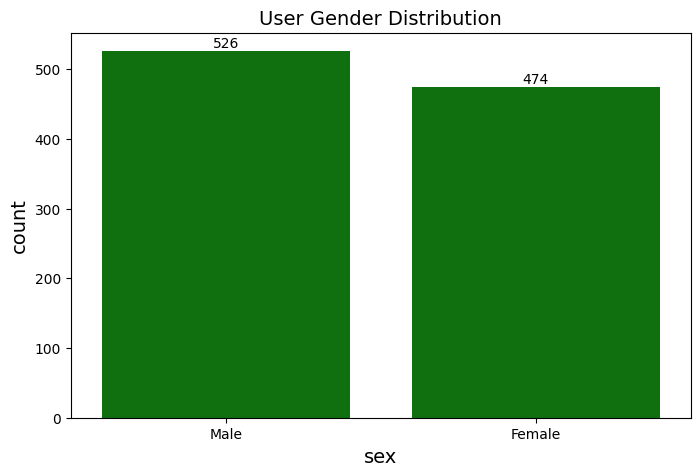

In [128]:
#①性别
import seaborn as sns
f,ax=plt.subplots(figsize=(8,5))
gender_counts=df['Gender'].value_counts()
sns.barplot(x=gender_counts.index,y=gender_counts.values,color='green')
plt.title('User Gender Distribution',fontsize=14)
plt.xlabel('sex',fontsize=14)
plt.ylabel('count',fontsize=14)
#为每个柱子添加详细的数字标签在（i，v+5)的位置，贴上数据标签str(v)
for i,v in enumerate(gender_counts.values):
    plt.text(i,v+5,str(v),ha='center',fontsize=10)
plt.savefig('用户性别分布.png',dpi=300)
plt.show()    

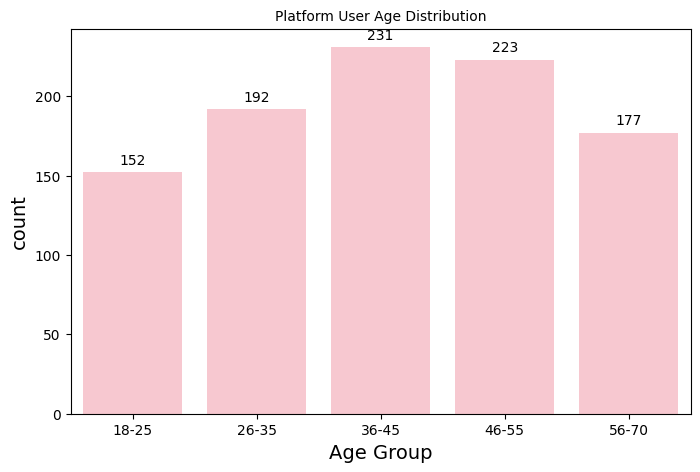

In [129]:
#②年龄分层
df['Age_group']=pd.cut(df['Age'],bins=[18,25,35,45,55,70],labels=['18-25','26-35','36-45','46-55','56-70'])
age_count=df['Age_group'].value_counts().sort_index()
x,ax=plt.subplots(figsize=(8,5))
sns.barplot(x=age_count.index,y=age_count.values,color='pink')
plt.title('Platform User Age Distribution',fontsize=10)
plt.xlabel('Age Group',fontsize=14)
plt.ylabel('count',fontsize=14)
#为每个柱子添加详细的数字标签在（i，v+5)的位置，贴上数据标签str(v)
for i,v in enumerate(age_count.values):
    plt.text(i,v+5,str(v),ha='center',fontsize=10)
plt.savefig('用户年龄分布.png',dpi=300)
plt.show()    

In [130]:
#③不同年龄段对应的总消费
total_consum=df.groupby('Age_group')['Total_Spending'].mean().astype(int).sort_index()
x,ax=plt.subplots(figsize=(8,5))
#hue让柱子按着数值大小进行自动变色
sns.barplot(y=total_consum.index,x=total_consum.values,hue=total_consum,palette='coolwarm')
plt.title('Platform User Average Spending',fontsize=10)
plt.ylabel('Age Group',fontsize=14)
plt.xlabel('Spending',fontsize=14)
#为每个柱子添加详细的数字标签在（i，v+5)的位置，贴上数据标签str(v)
for i,v in enumerate(total_consum.values):
    plt.text(i,v+50,str(v),ha='center',fontsize=10)
plt.savefig('年龄层消费对比.png',dpi=300)
plt.show()   

C:\Users\DELL\AppData\Local\Temp\ipykernel_9908\2824239822.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  total_consum=df.groupby('Age_group')['Total_Spending'].mean().astype(int).sort_index()


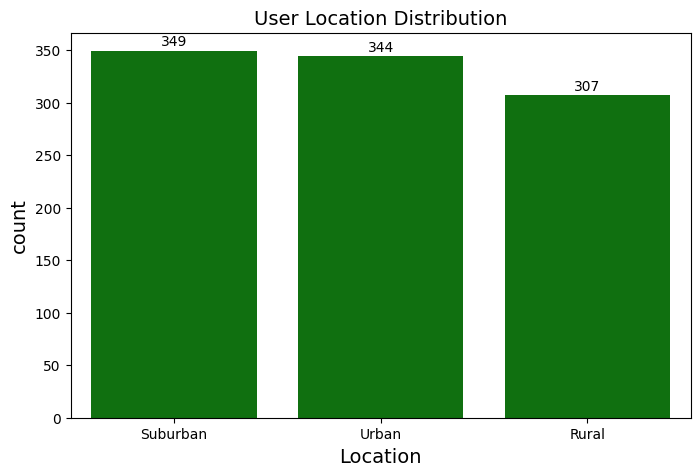

In [131]:
#④地域分布
f,ax=plt.subplots(figsize=(8,5))
location_counts=df['Location'].value_counts()
sns.barplot(x=location_counts.index,y=location_counts.values,color='green')
plt.title('User Location Distribution',fontsize=14)
plt.xlabel('Location',fontsize=14)
plt.ylabel('count',fontsize=14)
#为每个柱子添加详细的数字标签在（i，v+5)的位置，贴上数据标签str(v)
for i,v in enumerate(location_counts.values):
    plt.text(i,v+5,str(v),ha='center',fontsize=10)
plt.savefig('用户区域分布.png',dpi=300)
plt.show()    

C:\Users\DELL\AppData\Local\Temp\ipykernel_9908\573331980.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()#用于自动调节间距




In [132]:
#⑤兴趣及产品偏好分类图
interest_counts = df['Interests'].value_counts()
product_counts = df['Product_Category_Preference'].value_counts()
f, axes = plt.subplots(2, 1, figsize=(8, 10))
# 第一张图：兴趣分布
sns.barplot(y=interest_counts.index, x=interest_counts.values, ax=axes[0],hue=total_consum,palette='Reds')
axes[0].set_title('User Interests Distribution', fontsize=14)
axes[0].set_ylabel('Interests', fontsize=14)
axes[0].set_xlabel('Count', fontsize=14)
for i, v in enumerate(interest_counts.values):
    axes[0].text(i, v+5, str(v), ha='center', fontsize=10)
# 第二张图：品类偏好分布
sns.barplot(y=product_counts.index, x=product_counts.values, ax=axes[1], hue=total_consum,palette='RdBu_d')
axes[1].set_title('Product Category Distribution', fontsize=14)
axes[1].set_ylabel('Category', fontsize=14)
axes[1].set_xlabel('Count', fontsize=14)
for i, v in enumerate(product_counts.values):
    axes[1].text(i, v+5, str(v), ha='center', fontsize=10)
plt.tight_layout()#用于自动调节间距
plt.show()


（2.1）下面需要对用户的活跃度进行分析（主要行为方面进行分析）：直方图加上密度曲线的形式

①用户活跃度与流失特性分析（从用户上次登陆距离今天的天数获得）；

用户粘性中等：核心用户群体上次登陆在两周左右，既不是高频日活动，也不是长期流失；

潜在流失风险：25天以上仍有较多用户，需进一步关注是否有进一步流失可能

运营方式： 对于0-10天的低活跃用户，可以做新手引导或者专属福利，提升登录频率；对于15-22天的核心用户，可推送召回；对于25天以上用户，可做流失召回（优惠券、个性化推荐）

②用户粘性影响因素分析（根据订阅与非订阅用户网站浏览时间获得）：箱线图

通过箱线图对比邮件订阅用户与非邮件订阅用户的网站停留时长，发现订阅邮件订阅用户的停留时长没有显著优势；

两组均存在大量停留极短（0分钟）和停留极长（1000分钟）的用户；停留极短可能是新用户、误访问或流失用户；长停留客户：可能是高价值活跃用户或深度浏览用户

③浏览时长以及浏览页数对于购买频次的相关性：热力图加上相关性系数的形式

通过热力图可以发现停留时间以及浏览页数对于购买频率的相关性趋于零。即存在大量观光用户，他们贡献了流量活跃度但是未贡献GMV,这些用户有强烈的购买意向，等待转化触发






(2.2)将用户活跃特性（2.1）的内容分析进行可视化操作

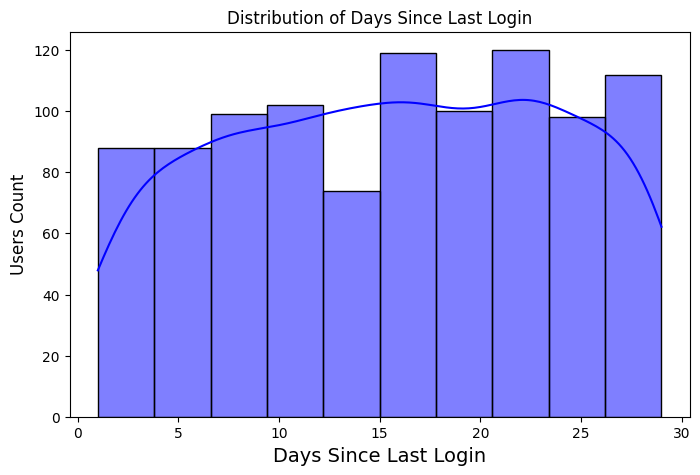

In [133]:
#①用户活跃度分析
# 用户上次登陆天数分布（判断用户活跃/流失情况）：采用直方图
plt.figure(figsize=(8,5))
sns.histplot(df['Last_Login_Days_Ago'], bins=10, kde=True, color='blue',edgecolor='black')
plt.xlabel('Days Since Last Login',fontsize=14)
plt.ylabel('Users Count',fontsize=12)
plt.title('Distribution of Days Since Last Login',fontsize=12)
plt.show()


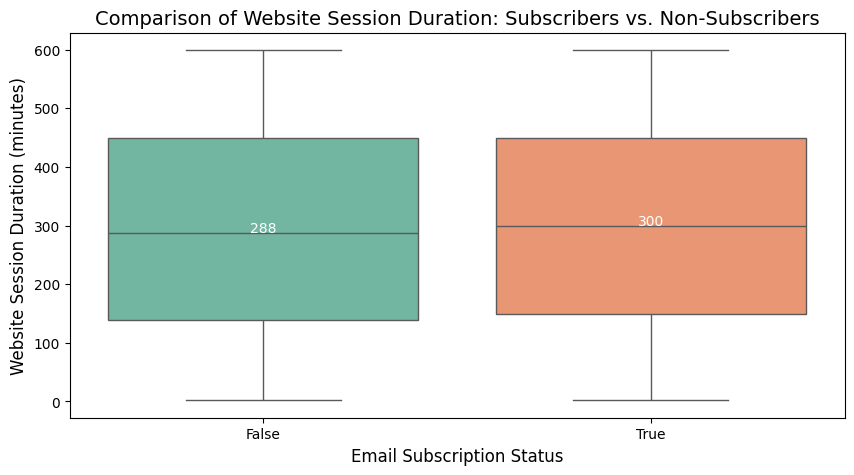

In [134]:
#②用户粘性影响因素分析
#  订阅用户活跃度对比 订阅用户vs.非订阅用户（分组用箱线图的形式）
plt.figure(figsize=(10, 5))
#hue按照分组进行不同染色，palette是染色方案
sns.boxplot(x='Newsletter_Subscription', y='Time_Spent_on_Site_Minutes', data=df,hue='Newsletter_Subscription', palette='Set2',legend=False)
medians = df.groupby('Newsletter_Subscription')['Time_Spent_on_Site_Minutes'].median() # 计算中位数
plt.title('Comparison of Website Session Duration: Subscribers vs. Non-Subscribers', fontsize=14)
plt.xlabel('Email Subscription Status', fontsize=12)
plt.ylabel('Website Session Duration (minutes)', fontsize=12)
for i, v in enumerate(medians):
    plt.text(i, v, f'{v:.0f}', ha='center', fontsize=10, color='white')
plt.savefig('订阅用户活跃度对比.png', dpi=300, bbox_inches='tight')
plt.show()

浏览时长与购买频次的相关性: -0.028
浏览页数与购买频次的相关性: 0.026


<Axes: >

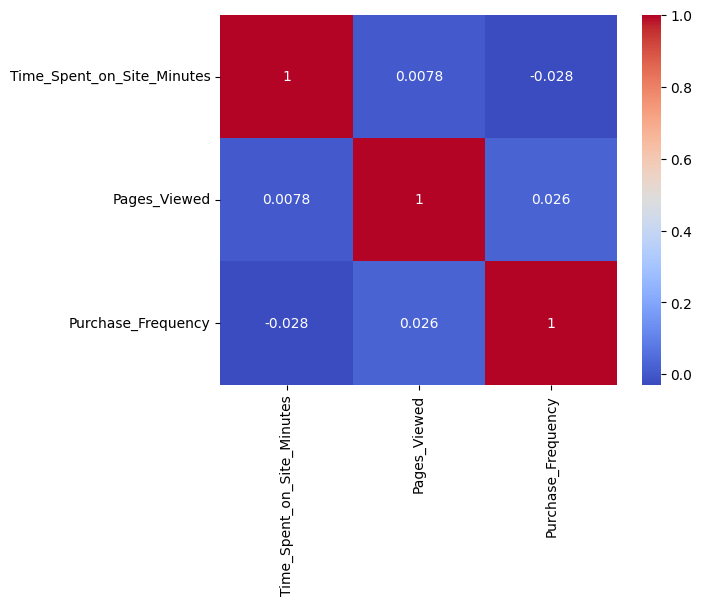

In [135]:
# ③浏览时长以及浏览页数对于购买频次的相关性
time_purchase_corr = df['Time_Spent_on_Site_Minutes'].corr(df['Purchase_Frequency'])
pages_purchase_corr = df['Pages_Viewed'].corr(df['Purchase_Frequency'])
print(f"浏览时长与购买频次的相关性: {time_purchase_corr:.3f}")
print(f"浏览页数与购买频次的相关性: {pages_purchase_corr:.3f}")
sns.heatmap(df[['Time_Spent_on_Site_Minutes', 'Pages_Viewed', 'Purchase_Frequency']].corr(), annot=True, cmap='coolwarm')

(3.1)将用户属性、行为特征和消费特征三个维度进行交叉考虑
传统RFM模型的局限性：R代表的是时间间隔，F代表的是频率，M代表的是花费金额；这三个指标进行组合，得到8类用户，从最值钱的最不值钱的。但是缺点是只看花钱看不到逛和互动

改良RFM模型：增加指标(意向+纠结+忠诚)

①意向度（用于衡量用户是否想买）：Satisfication=停留时长得分×0.5+浏览页数得分×0.5

②转化摩擦系数（衡量用户纠结程度）：Friction=浏览页数/（购买次数+1）#其中加1是为了防止分母为零，浏览的页面很多但是购买次数很少说明用户很纠结

③活跃度链接（衡量真忠诚还是假忠诚）：考虑上次登录距离当前时间以及是否订阅两个指标进行交叉考虑，分类打分Loyalty_score

④辅助分层（用于观测有钱不花的高潜望者，没钱不花很正常）：查看用户的购买力背景,根据用户的收入情况进行分类，划分33%分位数和66%分位数，作为分层阈值Icome_leval

⑤判别兴趣和品类偏好是否是匹配的Interest_Match


（3.2）将上述（3.1）改良后的RFM模型相应的指标应用到具体数据上进行分析

In [136]:
#(1)提取RFM三个核心指标
rfm_df=df[['User_ID','Last_Login_Days_Ago','Purchase_Frequency','Total_Spending']]
rfm_df.columns=['User_ID','R','F','M']
#(2)①通过构造的意向度Interest公式，得到其数值范围
#综合考虑三种情况；第一种使用默认公式进行计算；
#第二种所有值都一样，直接给50分；第三种反向计算，数值越大，兴趣度越低
def min_max_normalize(series,reverse=False):
        min_val,max_val=series.min(),series.max()
        if max_val==min_val:
            return pd.Series([50]*len(series))
        if reverse:
            return ((max_val-series)/(max_val-min_val))*100
        return ((series-min_val)/(max_val-min_val))*100
df['Time_Spent_Norm']=min_max_normalize(df['Time_Spent_on_Site_Minutes'])#停留时长
df['Pages_Viewed_Norm'] = min_max_normalize(df['Pages_Viewed'])#浏览的页面数量
df['Satisfaction']=0.5*df['Time_Spent_Norm']+0.5*df['Pages_Viewed_Norm']
#(3)②转化摩擦系数Friction的计算公式
df['Friction']=df['Pages_Viewed']/(df['Purchase_Frequency']+1)
#(4)③活跃度链接Loyality的计算公式
def calculate_loyalty(row):
        subscribed=row['Newsletter_Subscription']
        login_days=row['Last_Login_Days_Ago']
        #订阅且7天内登录
        if subscribed and login_days<7:
            return 3
        #未订阅但7天内登录
        elif not subscribed and login_days<7:
            return 2
        #订阅但7天以上未登录和未订阅但7天以上未登录
        else:
            return 1
df['loyalty_score']=df.apply(calculate_loyalty,axis=1)
#(5)④辅助分层,将收入分为了三个类别，收入的33%分位数和66%分位数作为分界点，分别为低收入、中等收入和高收入
df['Income_Level']=pd.qcut(df['Income'],q=3,labels=['Low','Medium','High'])
#(6)⑤兴趣匹配度Interest_Match的计算公式
df['Interest_Match']=(df['Interests']==df['Product_Category_Preference']).astype(int)
#(7)汇总以上分析结果
print(f"Satisfaction范围：[{df['Satisfaction'].min():.2f},{df['Satisfaction'].max():.2f}]")
print(f"Friction 范围: [{df['Friction'].min():.2f}, {df['Friction'].max():.2f}]")
print(f"Loyalty_Score 分布: {df['loyalty_score'].value_counts().to_dict()}")
print(f"Income_Level 分布: {df['Income_Level'].value_counts().to_dict()}")
print(f"Interest_Match 匹配率: {df['Interest_Match'].mean()*100:.1f}%")
df[['User_ID','Satisfaction','Friction','loyalty_score','Income_Level','Interest_Match']].head()


Satisfaction范围：[0.00,98.83]
Friction 范围: [0.10, 49.00]
Loyalty_Score 分布: {1: 824, 3: 99, 2: 77}
Income_Level 分布: {'Low': 334, 'High': 334, 'Medium': 332}
Interest_Match 匹配率: 0.0%


,User_ID,Satisfaction,Friction,loyalty_score,Income_Level,Interest_Match
0,#1,87.285385,4.750000,3,Low,0
1,#2,76.638400,5.000000,1,High,0
2,#3,25.460637,0.500000,1,High,0
3,#4,73.136516,7.250000,1,Medium,0
4,#5,13.646357,1.666667,3,Low,0


(3.3)关键性分布分析，进行可视化操作


高摩擦用户分析
高摩擦用户数量: 247
1.平均浏览页数：34.3
2.平均购买频次：1.6
3.平均消费金额：2514

高收入低消费群体分析
高收入低消费用户数量: 181
占高收入群体的比例：54.2%


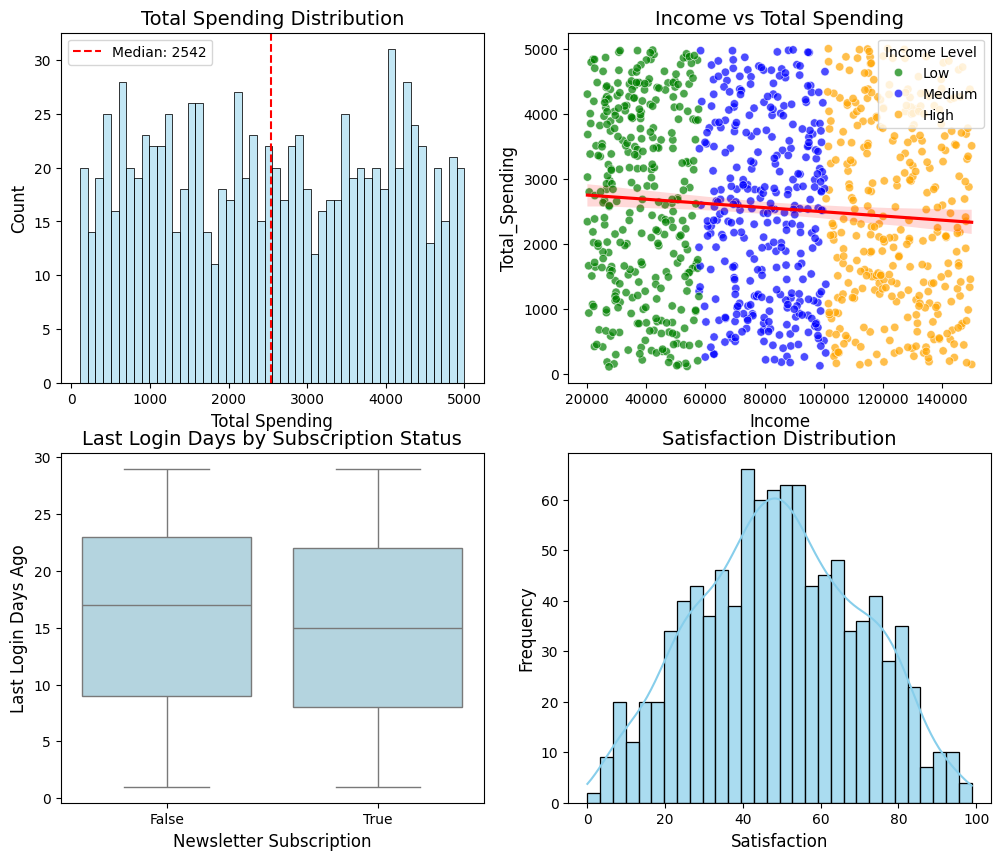

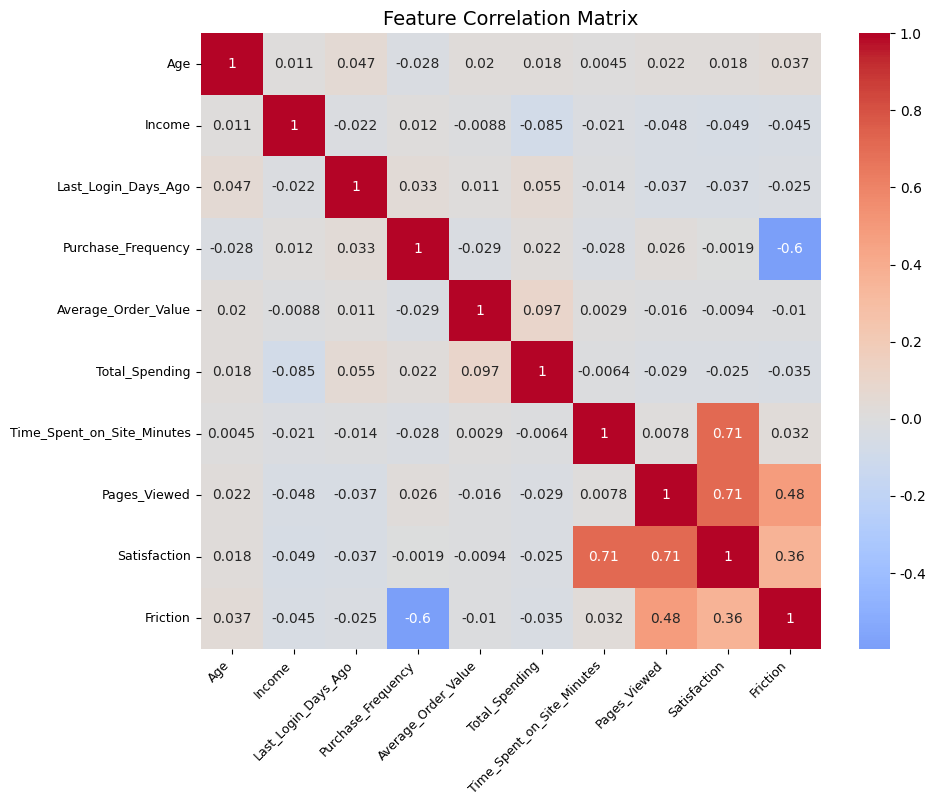

In [137]:
#(1)创建一个二乘二的画布
fig,axes=plt.subplots(2,2,figsize=(12,10))
#(2)①绘制总消费的直方图,并标出中位数的位置
sns.histplot(df['Total_Spending'], bins=50, edgecolor='black',alpha=0.5,color='skyblue', ax=axes[0,0])
axes[0,0].set_title('Total Spending Distribution', fontsize=14)
axes[0,0].set_xlabel('Total Spending', fontsize=12)
axes[0,0].set_ylabel('Count', fontsize=12)
axes[0,0].axvline(df['Total_Spending'].median(), color='red', linestyle='--', label=f'Median: {df["Total_Spending"].median():.0f}')
axes[0,0].legend()
#(3)②绘制散点图,查看不同收入群体的消费情况
color_map={'Low':'green','Medium':'blue','High':'orange'}
sns.scatterplot(x=df['Income'],y=df['Total_Spending'],hue=df['Income_Level'],palette=color_map,alpha=0.7,ax=axes[0,1])
axes[0,1].set_title('Income vs Total Spending', fontsize=14)
axes[0,1].set_xlabel('Income', fontsize=12)
axes[0,1].set_ylabel('Total Spending', fontsize=12)
axes[0,1].legend(title='Income Level')
sns.regplot(data=df,x='Income',y='Total_Spending',scatter=False,color='red',ax=axes[0,1])#回归趋势线
#(4)③绘制距离今天登录天数和是否订阅的箱线图
sns.boxplot(data=df, x='Newsletter_Subscription', y='Last_Login_Days_Ago', ax=axes[1,0],color='lightblue')
axes[1,0].set_title('Last Login Days by Subscription Status', fontsize=14)
axes[1,0].set_xlabel('Newsletter Subscription', fontsize=12)
axes[1,0].set_ylabel('Last Login Days Ago', fontsize=12)
#(5)④绘制satisfication的直方图
sns.histplot(df['Satisfaction'], bins=30, edgecolor='black',alpha=0.7,color='skyblue',kde=True,line_kws={'color':'darkred'}, ax=axes[1,1])
axes[1,1].set_title('Satisfaction Distribution', fontsize=14)
axes[1,1].set_xlabel('Satisfaction', fontsize=12)
axes[1,1].set_ylabel('Frequency', fontsize=12)
#(6)⑤绘制三个维度交叉变量关系的热力图
numeric_cols=['Age','Income','Last_Login_Days_Ago','Purchase_Frequency','Average_Order_Value','Total_Spending','Time_Spent_on_Site_Minutes','Pages_Viewed','Satisfaction','Friction']
fig,ax=plt.subplots(figsize=(10,8))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0, ax=ax)
ax.set_xticklabels(numeric_cols, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(numeric_cols, fontsize=9)
ax.set_title('Feature Correlation Matrix', fontsize=14)
#(7)⑥挑选出来高摩擦用户分析他们的浏览页数、购买频次、消费金额情况
high_friction=df[df['Friction']>df['Friction'].quantile(0.75)]
print('\n高摩擦用户分析')
print(f'高摩擦用户数量: {len(high_friction)}')
print(f"1.平均浏览页数：{high_friction['Pages_Viewed'].mean():.1f}")
print(f"2.平均购买频次：{high_friction['Purchase_Frequency'].mean():.1f}")
print(f"3.平均消费金额：{high_friction['Total_Spending'].mean():.0f}")
#(8)⑦高收入低消费群体分析
high_income_low_spend=df[(df['Income_Level']=='High') & (df['Total_Spending']<df['Total_Spending'].median())]
print('\n高收入低消费群体分析')
print(f'高收入低消费用户数量: {len(high_income_low_spend)}')
print(f"占高收入群体的比例：{len(high_income_low_spend)/len(df[df['Income_Level']=='High'])*100:.1f}%")

（4.1）RFM-satisfication 模型的构建

In [138]:
#（1）提取传统RFM模型的核心指标及定义的兴趣度Satisfaction指标进行归一化操作
#归一化函数,把任意一列数据缩放到0-100的范围
def min_max_normalize(series, reverse=False):#默认不反转，越大越好
    min_val, max_val = series.min(), series.max()
    if max_val == min_val:
        return pd.Series([50] * len(series))#中间分50，不偏高也不偏低，防止分母为零
    if reverse:#如果反转了就是越小越好，但这里没用到（false），好处可以同时使用两个函数
        return ((max_val - series) / (max_val - min_val)) * 100
    return ((series - min_val) / (max_val - min_val)) * 100
#①原始RFM模型的计算公式
df['R_Score'] = min_max_normalize(df['Last_Login_Days_Ago'], reverse=True)
df['F_Score'] = min_max_normalize(df['Purchase_Frequency'])
df['M_Score'] = min_max_normalize(df['Total_Spending'])
df['RFM_Score'] = 0.2 * df['R_Score'] + 0.3 * df['F_Score'] + 0.5 * df['M_Score']
#②添加兴趣度Satisfaction的计算公式
df['I_Weight'] = df['Satisfaction'] / 500  # 将兴趣度Satisfaction的范围缩放到0-0.2之间，作为权重
df['Final_Score'] = df['RFM_Score'] * (1 + df['I_Weight'])
#③输出各指标归一化后的结果
print(f"R_score范围: [{df['R_Score'].min():.2f}, {df['R_Score'].max():.2f}]")
print(f"F_score范围: [{df['F_Score'].min():.2f}, {df['F_Score'].max():.2f}]")
print(f"M_score范围: [{df['M_Score'].min():.2f}, {df['M_Score'].max():.2f}]")
print(f"RFM_Score范围: [{df['RFM_Score'].min():.2f}, {df['RFM_Score'].max():.2f}]")
print(f"Final_Score范围: [{df['Final_Score'].min():.2f}, {df['Final_Score'].max():.2f}]")

R_score范围: [0.00, 100.00]
F_score范围: [0.00, 100.00]
M_score范围: [0.00, 100.00]
RFM_Score范围: [4.72, 96.77]
Final_Score范围: [5.26, 105.06]


In [ ]:
#（2）用户分层画像分析
#①利用归一化整理后的数据，将用户进行分类统计（分别按照传统RFM和改进后的）
def classify_users(row):
    r = row['R_Score']
    f = row['F_Score']
    m = row['M_Score']
    s = row['Satisfaction']
    income = row['Income_Level']
    friction = row['Friction']
    l = row['loyalty_score']
    #传统RFM分层的逻辑
    if  r > 60 and f > 60 and m > 60:
        base_label = "Important Value Users"#重要价值用户
    elif r > 60 and m > 60 and f < 40:
        base_label = "Important Development Users"#重要发展用户
    elif r < 40 and f > 60 and m > 60:
        base_label = "Important Retention Users"#重要保持用户
    elif r < 40 and m > 60:
        base_label = "Important Win-Back Users"#重要挽留用户
    elif r > 60 and f > 40 and m < 40:
        base_label = "General Development Users"#一般发展用户
    elif r > 60 and f < 40 and m < 40:
        base_label = "General Maintenance Users"#一般维持用户
    elif r < 40 and f < 40 and m < 40:
            base_label = "Low-Value Users"#低价值用户
    else:
        base_label = "General Users"#一般用户   
    #修正后的指标判断（越容易误判的优先放到前面）
    if base_label in ["Low-Value Users", "General Maintenance Users"] and income == "High" and s > 60:
        return "High-Potential Sleeping Users"#高潜沉睡用户（rfm都小，r大fm小但这两类收入高意向度高）
    if income == "High" and s > 70 and f < 40 and m < 50:
        return "High-Spending Hesitant Users"#纠结土豪（高收入高意向但购买频率和金额低）
    if base_label in ["General Maintenance Users", "General Development Users"] and s > 80 and friction > df['Friction'].quantile(0.6):
        return "Potential Hesitant Users"#犹豫型潜力用户（r大fm小，rf大小，意向度高很纠结）
    if income == "Low" and s > 70 and f < 40:
        return "Invisible Active Users"#隐形活跃者（收入低，意向度高购买频率低）
    if income == "High" and r < 40 and m > 50:
        return "High-Potential At-Risk Users"#高潜流失客（高收入长时间不登花钱多）
    if m > 70 and f > 70 and s > 60:
        return "Core VIP Users"#核心VIP(花钱多购买次数多意向度高)
    if income == "Low" and s < 40 and m < 40:     
        return "Penny Pinchers / Low-Value Users"#羊毛党/低值（收入低意向高花钱少）
    return base_label
#②调用函数进行分层统计，用数据展示用户形象
df['User_Segment']=df.apply(classify_users,axis=1)
segment_stats=df.groupby('User_Segment').agg({'User_ID':'count','Total_Spending': 'mean','Purchase_Frequency': 'mean','Satisfaction': 'mean','Income': 'mean','Final_Score': 'mean'}).round(2)
segment_stats.columns = ['用户数', '平均消费', '平均购买频率', '平均意向分', '平均收入', '平均综合分']
segment_stats['占比(%)'] = (segment_stats['用户数'] / len(df) * 100).round(1)
segment_stats = segment_stats.sort_values('用户数', ascending=False)
#③数据可视化展示
print("/n用户统计分析")
print(segment_stats)
segment_stats.to_csv(f"E:/jupyter项目练习/RFM-RFI用户价值分层与ROI优化/segment_stats.csv", encoding='utf-8-sig')  

/n用户统计分析
                                  用户数     平均消费  平均购买频率  平均意向分       平均收入  \
User_Segment                                                               
General Users                     443  2368.12    5.17  48.80   84305.72   
General Development Users          80  1126.12    6.45  50.05   87473.72   
Important Win-Back Users           67  4134.42    2.57  46.53   59698.61   
High-Potential At-Risk Users       64  3990.70    4.92  44.09  121985.09   
Low-Value Users                    50  1036.52    1.68  42.79   94734.76   
Important Development Users        48  3873.96    1.62  48.91   81230.60   
General Maintenance Users          47  1055.40    1.47  45.83   91335.23   
Important Value Users              47  3960.19    7.47  42.28   73500.94   
Important Retention Users          39  4030.23    7.49  48.00   57995.92   
Invisible Active Users             34  2756.79    1.32  77.99   36273.32   
Penny Pinchers / Low-Value Users   33  1002.73    5.48  23.37   38499.45   
Cor

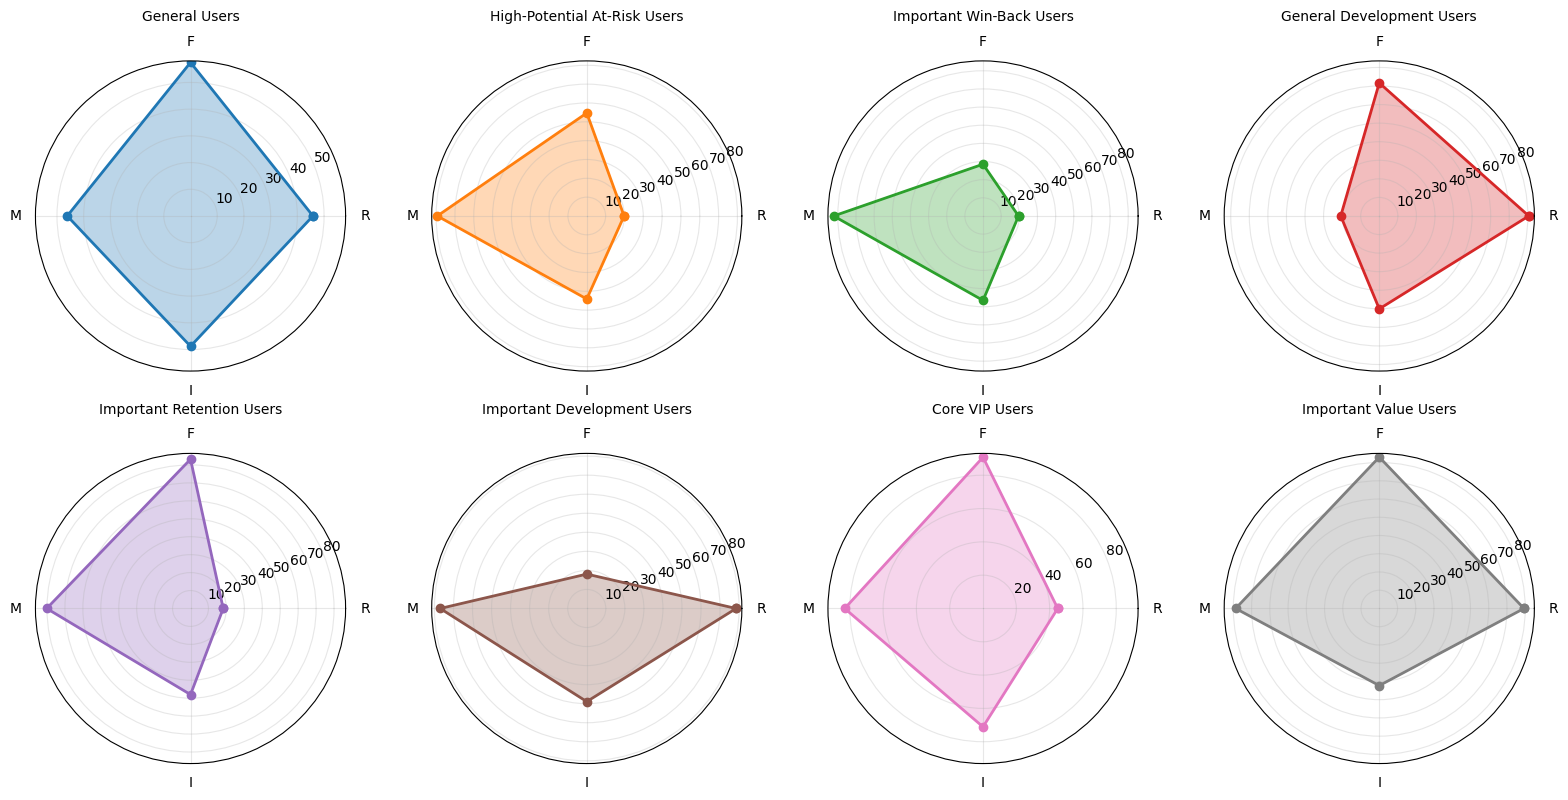

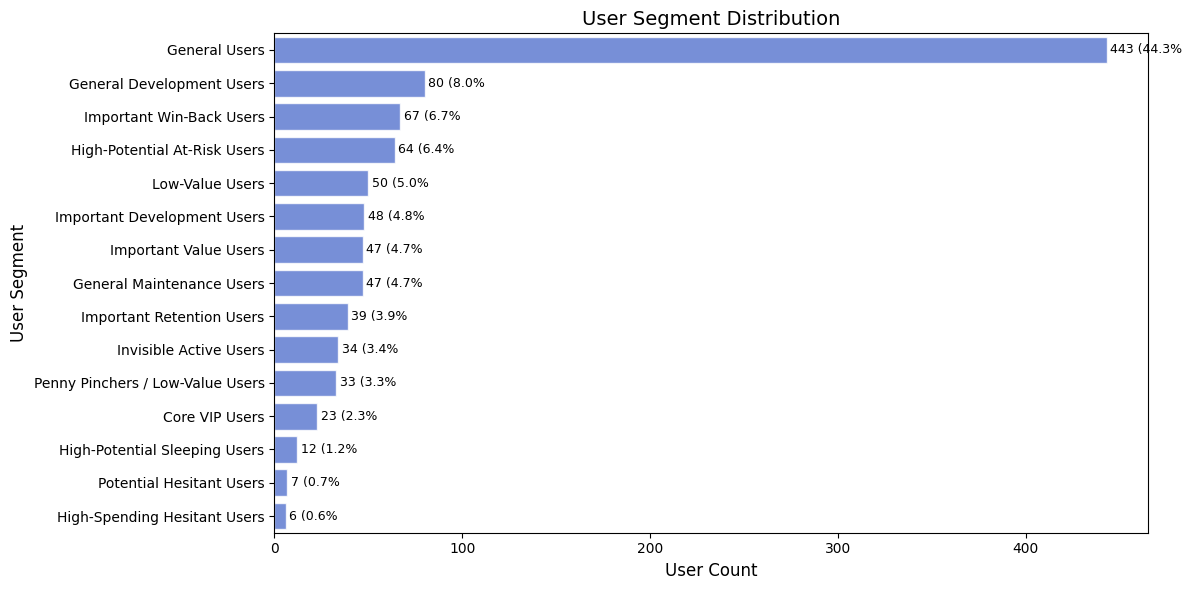

In [141]:
#(4.3)用户画像可视化分析（生成雷达图和分布柱状图）
#分层雷达图
segments=df['User_Segment'].unique()#去重，找不重复的
metrics=['R_Score','F_Score','M_Score','Satisfaction']
#计算每个分层的指标均值
segment_means=df.groupby('User_Segment')[metrics].mean()
#①绘制分层雷达图（极坐标图）
fig,axes=plt.subplots(2,4,figsize=(16,8),subplot_kw={'projection':'polar'})
axes=axes.flatten()#把2*4的二维数组转换为1*8的一维数组
#计算雷达图角度（metrics有4个指标，雷达图需要把4个点均匀分布在圆周上）
angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()#0到2pi之间均匀分布4个点，无终点，数组转列表
angles += angles[:1]#追加第一个角度实现雷达图闭合[0,90,180,270,0]
#循环绘制每个分层的雷达图
for idx, segment in enumerate(segments[:8]):
        if idx >= len(axes):
            break
        ax = axes[idx]
        #提取当前分层的指标值，闭合图形
        values = segment_means.loc[segment].tolist()
        values += values[:1]
        ax.fill(angles, values, alpha=0.3, color=sns.color_palette()[idx % len(sns.color_palette())])
        ax.plot(angles, values, 'o-', color=sns.color_palette()[idx % len(sns.color_palette())], linewidth=2)
        ax.set_xticks(angles[:-1])#去掉重复的最后一个角度
        ax.set_xticklabels(['R', 'F', 'M', 'I'], fontsize=10)
        ax.set_title(segment, fontsize=10, pad=10)
        ax.grid(True,alpha=0.3)
#隐藏未使用的子图
for idx in range(len(segments), len(axes)):
    axes[idx].set_visible(False)
plt.tight_layout()
plt.savefig('E:/jupyter项目练习/RFM-RFI用户价值分层与ROI优化/segment_radar.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()    
#②分层分布柱状图
segment_counts = df['User_Segment'].value_counts().reset_index()
segment_counts.columns=['User_Segment','Count']
segment_counts['Percentage'] = (segment_counts['Count'] / len(df) * 100).round(1)
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=segment_counts,x='Count',y='User_Segment',ax=ax,color='royalblue',alpha=0.8,edgecolor='white')
for i,(count,pct) in enumerate(zip(segment_counts['Count'],segment_counts['Percentage'])):
    ax.text(count+2,i,f'{count} ({pct}%',va='center',fontsize=9)
    ax.set_xlabel('User Count',fontsize=12)
    ax.set_ylabel('User Segment',fontsize=12)
    ax.set_title('User Segment Distribution', fontsize=14)
plt.tight_layout()
plt.savefig('E:/jupyter项目练习/RFM-RFI用户价值分层与ROI优化/segment_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()





第六阶段：ROI测算

【假设参数】
  总预算: 10000元
  优惠券成本: 10元/人
  平均客单价: 104元

【转化率假设】
  RFM前20%用户：自然转化率 20.0%，发券后 30.0%，边际提升 10.0%
  核心用户：自然转化率 25.0%，发券后 30.0%，边际提升 5.0%
  潜力用户：自然转化率 1.0%，发券后 20.0%，边际提升 19.0%

【方案A - 传统RFM策略】
  目标用户数: 200
  成本: 2000元
  边际收益（增量）: 2081元
  边际ROI: 4.0%

【方案B - 优化RFI策略】
  核心用户: 70
  新挖掘潜力用户: 89
  总目标用户数: 159
  实际成本: 1590元 (预算使用率: 15.9%)
  边际收益（增量）: 2123元
  边际ROI: 33.5%


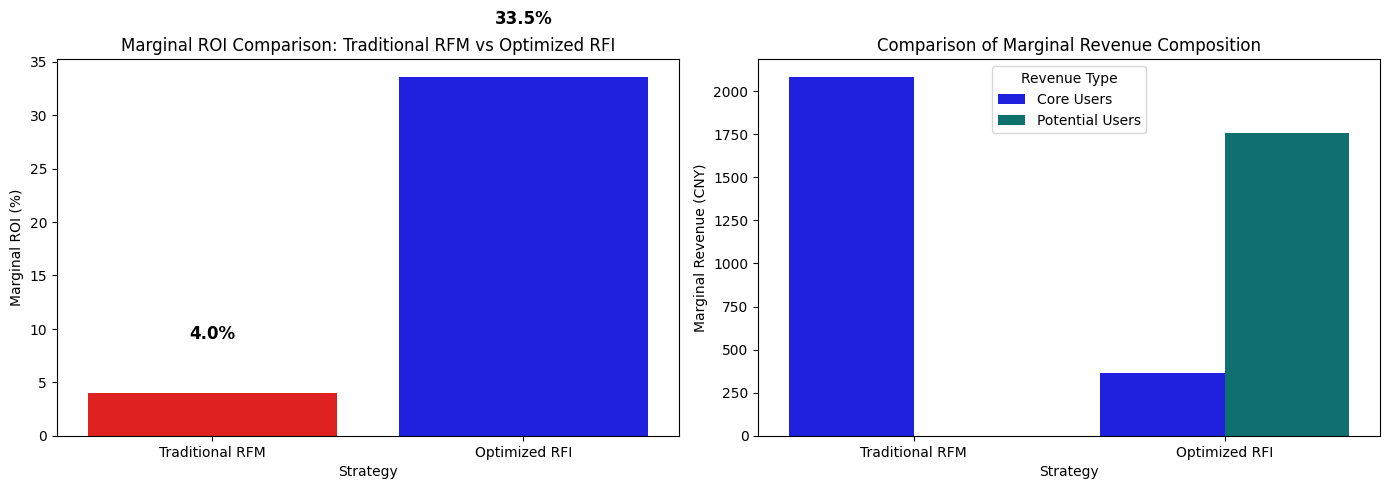

In [142]:
#（5.1）结果量化展示
def calculate_roi(df, output_dir):
    """ROI测算：传统RFM vs 优化RFI策略对比（边际收益法，参数可调）"""
    
    print("\n" + "=" * 50)
    print("第六阶段：ROI测算")
    print("=" * 50)
    
    # ================= 可调整参数=================
    total_budget = 10000          # 总预算（元）
    coupon_cost = 10               # 每张优惠券成本（元）
    aov = df['Average_Order_Value'].mean()  # 平均客单价（元）
    
    # 转化率假设
    # 核心用户
    core_natural = 0.25            # 核心用户无券自然转化率
    core_with_coupon = 0.30        # 核心用户发券后转化率
    # 潜力用户
    potential_natural = 0.01       # 潜力用户自然转化率
    potential_with_coupon = 0.20   # 潜力用户发券后转化率（可调高至20%-25%）
    # 一般用户（用于方案A的基线）
    general_natural = 0.02          # 一般用户自然转化率
    # RFM前20%用户的自然转化率（介于核心和一般之间）
    rfm20_natural = 0.20            # 可根据实际数据调整，例如：RFM高分用户通常转化率较高
    rfm20_with_coupon = 0.30        # 发券后转化率（通常不会超过核心用户）
    
    # 边际提升增量思维发券后转化率-自然转化率
    core_lift = core_with_coupon - core_natural
    potential_lift = potential_with_coupon - potential_natural
    rfm20_lift = rfm20_with_coupon - rfm20_natural
    #增量收益 = 目标用户数 × 边际提升 × 客单价（AOV）
    #ROI = (增量收益 - 成本) / 成本 × 100%（成本 = 用户数 × 单张优惠券成本）
    # ================= 方案A：传统RFM策略 =================
    top20_threshold = df['RFM_Score'].quantile(0.80)
    rfm_top20 = df[df['RFM_Score'] >= top20_threshold]
    target_a_count = min(len(rfm_top20), total_budget // coupon_cost)#预算约束既不超过高价值用户总数，也不超预算上限
    cost_a = target_a_count * coupon_cost
    incremental_revenue_a = target_a_count * rfm20_lift * aov
    roi_a = (incremental_revenue_a - cost_a) / cost_a * 100 if cost_a > 0 else 0
    
    # ================= 方案B：优化RFI策略 =================
    core_users = df[df['User_Segment'].isin(['Core VIP Users', 'Important Value Users'])]
    potential_users = df[df['User_Segment'].isin(['High-Spending Hesitant Users', 'High-Potential Sleeping Users', 'Potential Hesitant Users', 'High-Potential At-Risk Users'])]
    
    # 分配预算：优先核心用户（用80%预算），剩余给潜力用户
    core_count = min(len(core_users), int(total_budget * 0.8 / coupon_cost))
    remaining_budget = total_budget - core_count * coupon_cost
    potential_count = min(len(potential_users), remaining_budget // coupon_cost)
    target_b_count = core_count + potential_count
    cost_b = target_b_count * coupon_cost
    incremental_revenue_b = core_count * core_lift * aov + potential_count * potential_lift * aov
    roi_b = (incremental_revenue_b - cost_b) / cost_b * 100 if cost_b > 0 else 0
    
    # ================= 输出结果 =================
    print(f"\n【假设参数】")
    print(f"  总预算: {total_budget}元")
    print(f"  优惠券成本: {coupon_cost}元/人")
    print(f"  平均客单价: {aov:.0f}元")
    
    print(f"\n【转化率假设】")
    print(f"  RFM前20%用户：自然转化率 {rfm20_natural*100:.1f}%，发券后 {rfm20_with_coupon*100:.1f}%，边际提升 {rfm20_lift*100:.1f}%")
    print(f"  核心用户：自然转化率 {core_natural*100:.1f}%，发券后 {core_with_coupon*100:.1f}%，边际提升 {core_lift*100:.1f}%")
    print(f"  潜力用户：自然转化率 {potential_natural*100:.1f}%，发券后 {potential_with_coupon*100:.1f}%，边际提升 {potential_lift*100:.1f}%")
    
    print(f"\n【方案A - 传统RFM策略】")
    print(f"  目标用户数: {target_a_count}")
    print(f"  成本: {cost_a}元")
    print(f"  边际收益（增量）: {incremental_revenue_a:.0f}元")
    print(f"  边际ROI: {roi_a:.1f}%")
    
    print(f"\n【方案B - 优化RFI策略】")
    print(f"  核心用户: {core_count}")
    print(f"  新挖掘潜力用户: {potential_count}")
    print(f"  总目标用户数: {target_b_count}")
    print(f"  实际成本: {cost_b}元 (预算使用率: {cost_b/total_budget*100:.1f}%)")
    print(f"  边际收益（增量）: {incremental_revenue_b:.0f}元")
    print(f"  边际ROI: {roi_b:.1f}%")
    
    # ROI对比可视化
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    # ===== 子图1：边际ROI对比（柱状图）=====
    # 准备数据
    roi_data={'Strategy':['Traditional RFM', 'Optimized RFI'],'Marginal_ROI':[roi_a, roi_b]}
    sns.barplot(data=roi_data,x='Strategy',y='Marginal_ROI',hue='Strategy',ax=axes[0],palette=['red','blue'],legend=False)
    axes[0].set_ylabel('Marginal ROI (%)')#边际ROI (%)
    axes[0].set_title('Marginal ROI Comparison: Traditional RFM vs Optimized RFI', fontsize=12)#边际ROI对比：传统RFM vs 优化RFI
    for i, roi in enumerate([roi_a,roi_b]):
        axes[0].text(i, roi + 5, f'{roi:.1f}%', ha='center', fontsize=12, fontweight='bold')
    
    # ===== 子图2：边际收益构成对比（堆叠柱状图）=====
    # 准备堆叠数据
    stack_data = {
        'Strategy': ['Traditional RFM', 'Optimized RFI', 'Traditional RFM', 'Optimized RFI'],
        'Revenue_Type': ['Core Users', 'Core Users', 'Potential Users', 'Potential Users'],
        'Marginal_Revenue': [
            incremental_revenue_a, core_count * core_lift * aov,
            0, potential_count * potential_lift * aov
        ]
    }
    sns.barplot(data=stack_data,x='Strategy',y='Marginal_Revenue',hue='Revenue_Type',ax=axes[1],palette=['blue','teal'])
    axes[1].set_ylabel('Marginal Revenue (CNY)')#边际收益 (元)
    axes[1].set_title('Comparison of Marginal Revenue Composition', fontsize=12)#边际收益构成对比
    axes[1].legend(title='Revenue Type')
    
    plt.tight_layout()
    plt.savefig(f'{output_dir}/roi_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    
    return {
        'strategy_a': {
            'target_count': int(target_a_count),
            'cost': cost_a,
            'incremental_revenue': incremental_revenue_a,
            'marginal_roi': roi_a
        },
        'strategy_b': {
            'core_count': int(core_count),
            'potential_count': int(potential_count),
            'total_count': int(target_b_count),
            'actual_cost': cost_b,
            'budget_used_ratio': cost_b/total_budget,
            'incremental_revenue': incremental_revenue_b,
            'marginal_roi': roi_b
        },
        'params': {
            'budget': total_budget,
            'coupon_cost': coupon_cost,
            'aov': aov,
            'rfm20_lift': rfm20_lift,
            'core_lift': core_lift,
            'potential_lift': potential_lift
        }
    }
roi_results = calculate_roi(df, "E:/jupyter项目练习/RFM-RFI用户价值分层与ROI优化")


（6.1）最终业务结论

①优化 RFI 策略显著优于传统 RFM 策略 在边际增量收益基本持平的前提下，优化 RFI 策略仅使用 15.9% 的预算，就实现了 33.5% 的边际 ROI，远高于传统 RFM 策略的 4.0%，预算效率与投入产出比大幅提升。

②潜力用户是提升 ROI 的关键增量来源 潜力用户边际转化提升高达 19%，远高于核心用户与 RFM 头部用户，通过 RFI 模型精准挖掘这部分人群，能以更低成本撬动更高转化。

③多维度行为指标让用户分层更科学 新增 I_Score、Friction、L_Score 后，模型从 “只看历史消费” 升级为 “消费 + 意向 + 摩擦 + 粘性” 的综合判断，能够识别传统 RFM 遗漏的高潜人群。

④特征使用应遵循业务逻辑，而非盲目入模 购买力（Income_Level）等背景信息更适合作为分层标签，而非纳入综合评分，体现了 “业务理解优先于特征堆砌” 的建模思路。